# Simulator parameters

Parameters of the simulated detector measured on the real Walnut 1 data.

## 1a. Read noise and per-pixel offset

The difference of two darks cancels the fixed per-pixel offset and leaves only temporal noise:
var(D1 − D2) = 2 σ_read². Row offsets, column offsets and the slow component (residual image)
can change between orbits, so they are removed before measuring.

In [2]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import tifffile
from scipy.ndimage import gaussian_filter

DATA = Path("~/dati/walnut/Walnut1/Projections/tubeV1").expanduser()
ROOT = DATA.parent
ORBITS = ["tubeV1", "tubeV2", "tubeV3"]

darks = {
    orb: tifffile.imread(ROOT / orb / "di000000.tif").astype(np.float64)
    for orb in ORBITS
}
for orb, d in darks.items():
    print(f"{orb}: shape {d.shape}, mean {d.mean():.1f}, std {d.std():.2f}")

<TiffTag.fromfile> raised TiffFileError('<tifffile.TiffTag 320 @1493217> invalid value offset 0')
<TiffTag.fromfile> raised TiffFileError('<tifffile.TiffTag 320 @1493217> invalid value offset 0')
<TiffTag.fromfile> raised TiffFileError('<tifffile.TiffTag 320 @1493217> invalid value offset 0')


tubeV1: shape (768, 972), mean 342.7, std 11.14
tubeV2: shape (768, 972), mean 359.4, std 11.60
tubeV3: shape (768, 972), mean 364.9, std 11.36


In [3]:
def clean(img, slow_sigma=15):
    """Remove row offsets, column offsets and the slow (large-scale) component."""
    out = img - img.mean(axis=1, keepdims=True)  # one mean per row
    out = out - out.mean(axis=0, keepdims=True)  # one mean per column
    return out - gaussian_filter(out, slow_sigma)


def spread(x):
    """Standard deviation and a robust version (half the 16-84 percentile range)."""
    p16, p84 = np.percentile(x, [16, 84])
    return x.std(), (p84 - p16) / 2

In [4]:
s_tot, s_tot_rob = spread(clean(darks["tubeV1"]))
print(f"single dark tubeV1 cleaned: std {s_tot:.2f}, robust {s_tot_rob:.2f}\n")

pairs = [("tubeV1", "tubeV2"), ("tubeV1", "tubeV3"), ("tubeV2", "tubeV3")]
for a, b in pairs:
    s, s_rob = spread(clean(darks[a] - darks[b]))
    print(f"{a} - {b}: sigma_read {s / np.sqrt(2):.2f}, robust {s_rob / np.sqrt(2):.2f}")

single dark tubeV1 cleaned: std 1.35, robust 1.27

tubeV1 - tubeV2: sigma_read 0.59, robust 0.58
tubeV1 - tubeV3: sigma_read 0.57, robust 0.57
tubeV2 - tubeV3: sigma_read 0.56, robust 0.55


In [5]:
for sig in [5, 10, 15, 30]:
    s, _ = spread(clean(darks["tubeV1"] - darks["tubeV2"], slow_sigma=sig))
    print(f"slow_sigma {sig:2d}: sigma_read {s / np.sqrt(2):.3f}")

slow_sigma  5: sigma_read 0.548
slow_sigma 10: sigma_read 0.563
slow_sigma 15: sigma_read 0.585
slow_sigma 30: sigma_read 0.662


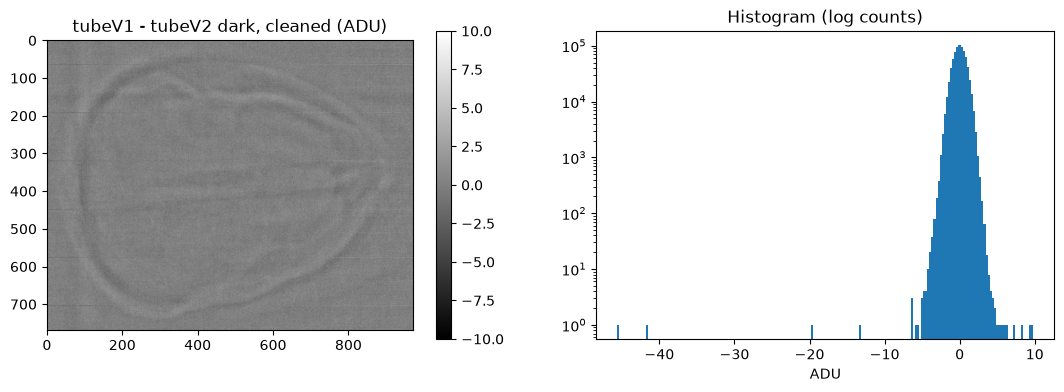

In [6]:
r = clean(darks["tubeV1"] - darks["tubeV2"])

fig, ax = plt.subplots(1, 2, figsize=(13, 4))
im = ax[0].imshow(r, cmap="gray", vmin=-10, vmax=10)
ax[0].set_title("tubeV1 - tubeV2 dark, cleaned (ADU)")
fig.colorbar(im, ax=ax[0])
ax[1].hist(r.ravel(), bins=200, log=True)
ax[1].set_xlabel("ADU")
ax[1].set_title("Histogram (log counts)")
plt.show()

In [7]:
sigmas = [2, 3, 5, 10, 15, 30]
print("slow_sigma  read(V1-V2)  total(V1 alone)  offset")
for sig in sigmas:
    s_diff, _ = spread(clean(darks["tubeV1"] - darks["tubeV2"], slow_sigma=sig))
    s_one, _ = spread(clean(darks["tubeV1"], slow_sigma=sig))
    s_read = s_diff / np.sqrt(2)
    s_off = np.sqrt(s_one**2 - s_read**2)
    print(f"{sig:10d}  {s_read:11.3f}  {s_one:15.3f}  {s_off:6.3f}")

slow_sigma  read(V1-V2)  total(V1 alone)  offset
         2        0.527            1.279   1.166
         3        0.539            1.299   1.182
         5        0.548            1.312   1.192
        10        0.563            1.327   1.202
        15        0.585            1.352   1.219
        30        0.662            1.495   1.341


In [8]:
SLOW_SIGMA = 3  # small enough to remove the walnut edges; noise loss corrected below


def keep_factor(s):
    """Fraction of white-noise std that survives clean() with slow_sigma = s."""
    return np.sqrt(1 - 3 / (4 * np.pi * s**2))


k = keep_factor(SLOW_SIGMA)
reads = []
for a, b in [("tubeV1", "tubeV2"), ("tubeV1", "tubeV3"), ("tubeV2", "tubeV3")]:
    s, _ = spread(clean(darks[a] - darks[b], slow_sigma=SLOW_SIGMA))
    reads.append(s / np.sqrt(2) / k)
    print(f"{a} - {b}: sigma_read (corrected) {reads[-1]:.3f}")

sigma_read_meas = np.mean(reads)  # includes quantisation: compare with simulated data
s_one, _ = spread(clean(darks["tubeV1"], slow_sigma=SLOW_SIGMA))
total = s_one / k
offset_px = np.sqrt(total**2 - sigma_read_meas**2)
sigma_read_sim = np.sqrt(sigma_read_meas**2 - 1 / 12)  # stage 7: rounding added at stage 8

print(f"\nsigma_read measured (with rounding): {sigma_read_meas:.3f} ADU")
print(f"total per-pixel spread, one dark:     {total:.3f} ADU")
print(f"per-pixel offset (stage 6):           {offset_px:.3f} ADU")
print(f"electronic read noise (stage 7):      {sigma_read_sim:.3f} ADU")

tubeV1 - tubeV2: sigma_read (corrected) 0.547
tubeV1 - tubeV3: sigma_read (corrected) 0.542
tubeV2 - tubeV3: sigma_read (corrected) 0.538

sigma_read measured (with rounding): 0.542 ADU
total per-pixel spread, one dark:     1.317 ADU
per-pixel offset (stage 6):           1.200 ADU
electronic read noise (stage 7):      0.459 ADU


**Result 1a.** Read noise and per-pixel offset (slow_sigma = 3, noise loss of the filter corrected):

| Quantity | Value (ADU) | Use |
|---|---|---|
| σ_read measured, includes rounding | 0.542 | target for the simulator validation |
| Per-pixel offset | 1.20 | stage 6 |
| Electronic read noise, √(σ_read² − 1/12) | 0.459 | stage 7 (stage 8 adds the rounding) |

- The 2.5 ADU per-pixel spread found in Milestone 1 was mostly residual image: removing the slow
  component lowers it to 1.32 ADU.
- With slow_sigma ≥ 15 the walnut edges survive in the difference of two darks and inflate σ_read
  (0.66 at slow_sigma = 30).
- Offset level differs between orbits (342.7, 359.4, 364.9 ADU): the dark of one orbit must not be
  used for another.
- About ten pixels change offset by 10–45 ADU between orbits: candidates for Milestone 3.

std of row means (raw):        10.48 ADU
std of fast row offsets:       8.43 ADU
std of row-to-row jumps, raw:  12.34 ADU
std of row-to-row jumps, fast: 12.34 ADU
correlation tubeV1 vs tubeV2:  1.000

row_sigma  5: std of fast row offsets 8.20 ADU
row_sigma 10: std of fast row offsets 8.43 ADU
row_sigma 20: std of fast row offsets 8.55 ADU
row_sigma 40: std of fast row offsets 8.64 ADU


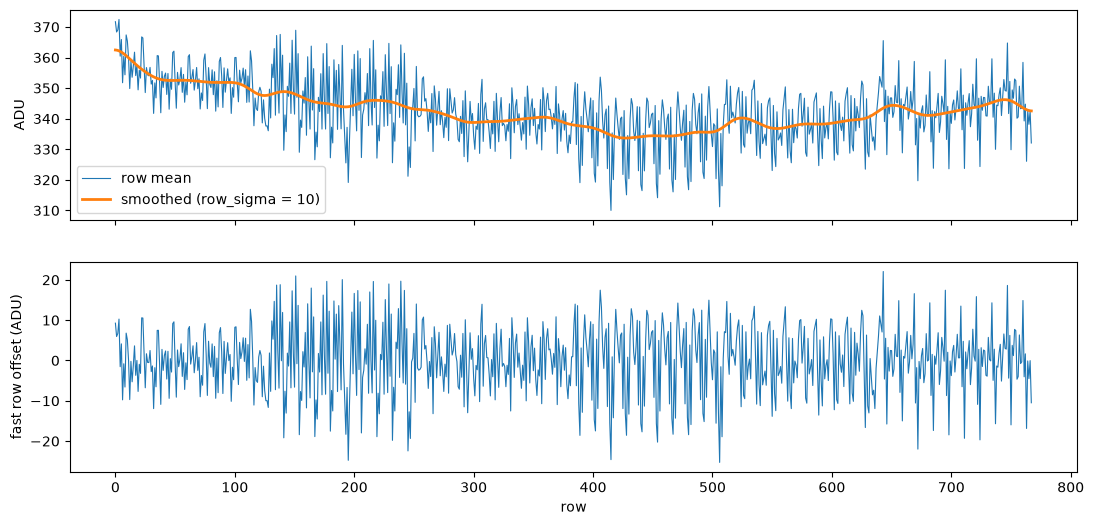

In [9]:
from scipy.ndimage import gaussian_filter1d

ROW_SIGMA = 10  # rows; the smooth part of the row means is residual image


def fast_rows(dark, row_sigma=ROW_SIGMA):
    """Row means minus their smoothed version: fast row-to-row offsets."""
    m = dark.mean(axis=1)  # one value per row (768)
    return m - gaussian_filter1d(m, row_sigma), m


fast1, m1 = fast_rows(darks["tubeV1"])
fast2, _ = fast_rows(darks["tubeV2"])

print(f"std of row means (raw):        {m1.std():.2f} ADU")
print(f"std of fast row offsets:       {fast1.std():.2f} ADU")
print(f"std of row-to-row jumps, raw:  {np.diff(m1).std():.2f} ADU")
print(f"std of row-to-row jumps, fast: {np.diff(fast1).std():.2f} ADU")
print(f"correlation tubeV1 vs tubeV2:  {np.corrcoef(fast1, fast2)[0, 1]:.3f}\n")

for s in [5, 10, 20, 40]:
    f, _ = fast_rows(darks["tubeV1"], s)
    print(f"row_sigma {s:2d}: std of fast row offsets {f.std():.2f} ADU")

rows = np.arange(m1.size)
fig, ax = plt.subplots(2, 1, figsize=(13, 6), sharex=True)
ax[0].plot(rows, m1, lw=0.8, label="row mean")
ax[0].plot(rows, m1 - fast1, lw=2, label=f"smoothed (row_sigma = {ROW_SIGMA})")
ax[0].set_ylabel("ADU")
ax[0].legend()
ax[1].plot(rows, fast1, lw=0.8)
ax[1].set_xlabel("row")
ax[1].set_ylabel("fast row offset (ADU)")
plt.show()

In [10]:
ROW_SIGMA = 20  # eats 1.3% of the stripes, no sign of the slow part leaking in
row_offsets, _ = fast_rows(darks["tubeV1"], ROW_SIGMA)

print(f"row offsets: {row_offsets.size} values, std {row_offsets.std():.2f} ADU")
print(f"std of row-to-row jumps: {np.diff(row_offsets).std():.2f} ADU (real dark: 12.34)")

row offsets: 768 values, std 8.55 ADU
std of row-to-row jumps: 12.34 ADU (real dark: 12.34)


## 1b. Row offsets

Row means of the dark = fixed row offsets (fast) + residual image (slow). The fast part is the
row means minus their Gaussian-smoothed version (row_sigma = 20 rows); these 768 values are the
true row offsets of the simulator (stage 6).

- Row offsets are independent from row to row: std of the jumps / √2 = 8.73 ADU, std of the
  offsets corrected for the part removed by the smoothing = 8.66 ADU.
- The pattern is identical in the darks of different orbits (correlation 1.000); only the mean
  level changes. Row offsets are a fixed property of the detector.
- Validation target for the simulated dark: std of the row-to-row jumps = 12.34 ADU.

<TiffTag.fromfile> raised TiffFileError('<tifffile.TiffTag 320 @1493217> invalid value offset 0')
<TiffTag.fromfile> raised TiffFileError('<tifffile.TiffTag 320 @1493217> invalid value offset 0')


std of rel, whole image: 0.62 %
std of rel, crop:        0.53 %


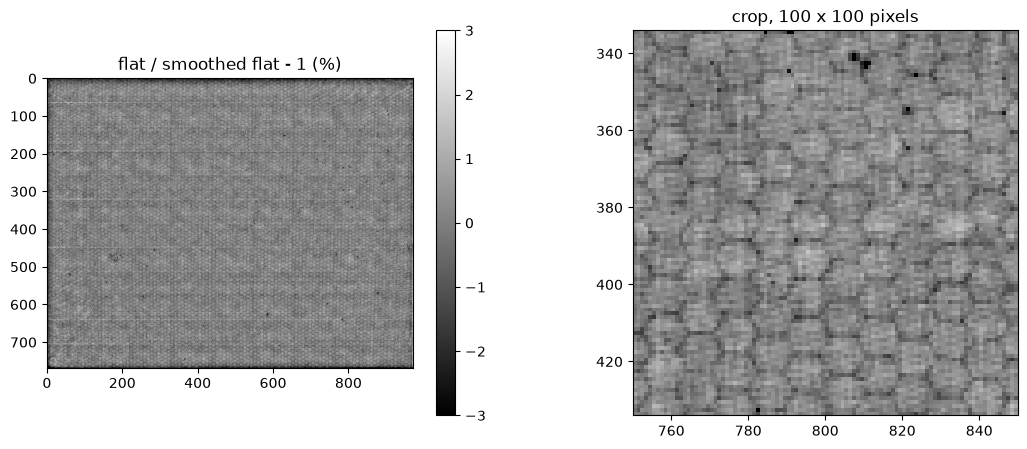

In [11]:
flats = [
    tifffile.imread(DATA / f"io00000{i}.tif").astype(np.float64) for i in (0, 1)
]
signal = (flats[0] + flats[1]) / 2 - darks["tubeV1"]  # mean of the two flats, dark removed
beam = gaussian_filter(signal, 15)                     # smooth part: beam profile
rel = signal / beam - 1                                # relative deviation (0.01 = 1%)

print(f"std of rel, whole image: {100 * rel.std():.2f} %")

r0, c0 = 334, 750  # 100 x 100 crop where the beam is brightest
crop = rel[r0:r0 + 100, c0:c0 + 100]
print(f"std of rel, crop:        {100 * crop.std():.2f} %")

fig, ax = plt.subplots(1, 2, figsize=(13, 5))
im = ax[0].imshow(100 * rel, cmap="gray", vmin=-3, vmax=3)
ax[0].set_title("flat / smoothed flat - 1 (%)")
fig.colorbar(im, ax=ax[0])
ax[1].imshow(100 * crop, cmap="gray", vmin=-3, vmax=3,
             extent=[c0, c0 + 100, r0 + 100, r0])  # axis labels = real row/column numbers
ax[1].set_title("crop, 100 x 100 pixels")
plt.show()

## 1c. Gain map: hexagonal pattern

Relative gain map: rel = (mean flat − dark) / Gaussian-smoothed version (σ = 15 px) − 1.

- Hexagonal cells, ~10 px between centres vertically and ~8.7 px between columns horizontally
  (ratio √3/2 of a regular honeycomb, columns staggered). Cell size ≈ 1.5 mm, i.e. ~20 physical
  pixels. Expected NPS peak near 0.1 cycles/pixel (Milestone 4).
- Std of rel: 0.53 % in a bright 100 × 100 crop, 0.62 % over the whole image (the by-eye estimate
  of 1–2 % was too high). Quantum noise contributes ~0.05 %, i.e. ~1 % of the variance: the
  pattern is fixed.
- Decision: the simulator uses the measured map itself (option B), after replacing anomalous
  pixels, replicated in 2×2 blocks on the physical grid. Binning then returns the measured map
  exactly. A synthetic honeycomb was not used: flat-field correction removes any multiplicative
  pattern, so the choice cannot change the calibration results.

dim   : beam   8439 ADU, stripes std 28.34 ADU = 0.235 %
bright: beam  12730 ADU, stripes std 46.15 ADU = 0.258 %


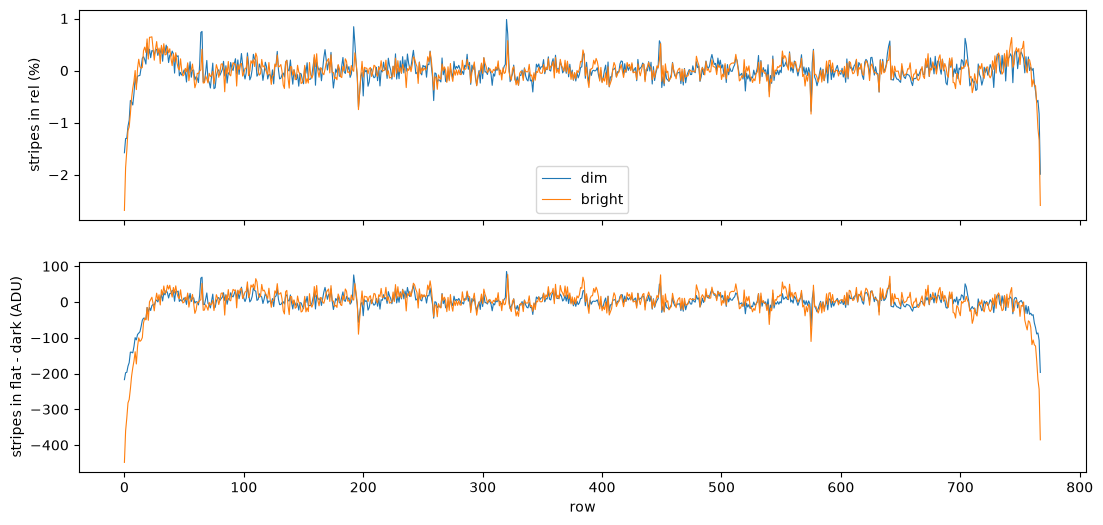

In [12]:
def fast_profile(img, cols, row_sigma=ROW_SIGMA):
    """Mean of each row over the given columns, minus its smoothed version."""
    m = img[:, cols].mean(axis=1)
    return m - gaussian_filter1d(m, row_sigma)


zones = {"dim": slice(30, 230), "bright": slice(700, 900)}  # skip the first ~20 edge columns
prof_adu, prof_rel = {}, {}
for name, cols in zones.items():
    prof_adu[name] = fast_profile(signal, cols)
    prof_rel[name] = fast_profile(rel, cols)
    print(f"{name:6s}: beam {beam[:, cols].mean():6.0f} ADU, "
          f"stripes std {prof_adu[name].std():5.2f} ADU = {100 * prof_rel[name].std():.3f} %")

fig, ax = plt.subplots(2, 1, figsize=(13, 6), sharex=True)
for name in zones:
    ax[0].plot(100 * prof_rel[name], lw=0.8, label=name)
    ax[1].plot(prof_adu[name], lw=0.8, label=name)
ax[0].set_ylabel("stripes in rel (%)")
ax[1].set_ylabel("stripes in flat - dark (ADU)")
ax[1].set_xlabel("row")
ax[0].legend()
plt.show()

## 1d. Horizontal lines in the gain map: gain or offset?

Test: the lines are compared where the beam is weak (columns 30–229, 8439 ADU) and strong
(columns 700–899, 12730 ADU). A gain effect scales with the beam (same in %), an offset does not
(same in ADU).

- Ratio strong/weak: 1.63 in ADU (beam ratio 1.51), 1.10 in % → multiplicative: the lines stay
  in the gain map.
- Isolated lines roughly every 128 rows (≈ 64, 192, 320, 448, 576, 704), probably readout-block
  boundaries.
- The first and last ~20 rows drop by up to 2.6 %: detector edge or smoothing artefact, to check.